# Imports and Reading data

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
plt.style.use('ggplot')
pd.set_option('display.max_columns', 200)


In [ ]:
df_gain1amp02fre6 = pd.read_csv('OTO-ESC_fix-1_0.2_6-100kshots.csv')


# Data understanding

In [ ]:
df_gain1amp02fre6.shape


In [ ]:
df_gain1amp02fre6.columns


In [ ]:
df_gain1amp02fre6.head(5)


# Feature understanding

In [ ]:
dfs = {
    'gain 1 amp 0.2 fre 6': df_gain1amp02fre6,
}


In [ ]:
cv = df_gain1amp02fre6['choose_ESC'].value_counts().head(10).plot(kind='bar', title='Convergence count')
cv.set_xlabel('ESC outperforms the fixed fuel-ratio benchmark')
cv.set_ylabel('Counts')


# Feature relationship

## Energy vs. other features

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True)

for ax, (name, df) in zip(axes.flat, dfs.items()):
    df.plot(
        kind='scatter',
        x='convergence_time',
        y='energy_ESC',
        ax=ax,
        title=name
    )
    ax.set_xlabel('Convergence time')
    ax.set_ylabel('Energy generated using ESC')

plt.tight_layout()
plt.show()


In [ ]:
params = ['optimizer_gain', 'dither_amplitude', 'dither_frequency']

for p in params:
    fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True)

    for ax, (name, df) in zip(axes.flat, dfs.items()):
        df.plot(
            kind='scatter',
            x=p,
            y='energy_ESC',
            ax=ax,
            title=name
        )
        ax.set_xlabel(p)
        ax.set_ylabel('Energy generated using ESC')

    fig.suptitle(f'Energy generated using ESC vs {p}')
    plt.tight_layout()
    plt.show()


## Symmetrical ESC parameter analysis

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

# ----- Setup -----

feature_cols = ['optimizer_gain', 'dither_amplitude', 'dither_frequency']
target = 'choose_ESC'

pairs = [
    ('gain 1 amp 0.2 fre 6', 'gain 1 amp 0.2 fre 6'),
]

def to_tensors(df):
    X = torch.tensor(df[feature_cols].values, dtype=torch.float32)
    y = torch.tensor(df[target].values, dtype=torch.float32).reshape(-1, 1)
    return X, y

def make_model(n):
    return nn.Sequential(
        nn.Linear(n, 32), nn.ReLU(),
        nn.Linear(32, 16), nn.ReLU(),
        nn.Linear(16, 1)
    )

def train(model, train_loader, Xtr, ytr, Xcv, ycv, epochs=300, lr=0.01):
    loss_fn = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {'loss': [], 'val_loss': []}

    for epoch in range(epochs):
        model.train()
        for xb, yb in train_loader:
            optimizer.zero_grad()
            outputs = model(xb)
            loss = loss_fn(outputs, yb)
            loss.backward()
            optimizer.step()

        with torch.no_grad():
            model.eval()
            train_loss = loss_fn(model(Xtr), ytr)
            val_loss = loss_fn(model(Xcv), ycv)
        history['loss'].append(float(train_loss))
        history['val_loss'].append(float(val_loss))
    return history


In [ ]:
# ----- Train on one dataset of each pair, test on the other -----

results = {}

for train_name, test_name in pairs:
    df_train = dfs[train_name][feature_cols + [target]]
    df_test = dfs[test_name][feature_cols + [target]]

    tr, cv = train_test_split(df_train, test_size=0.20, random_state=1)

    Xtr_p, ytr_p = to_tensors(tr)
    Xcv_p, ycv_p = to_tensors(cv)
    Xte_p, _ = to_tensors(df_test)

    loader = DataLoader(TensorDataset(Xtr_p, ytr_p), batch_size=100, shuffle=True)

    torch.manual_seed(1)
    model = make_model(Xtr_p.shape[1])

    history = train(model, loader, Xtr_p, ytr_p, Xcv_p, ycv_p)

    plt.plot(history['loss'], label='train loss')
    plt.plot(history['val_loss'], label='cv loss')
    plt.title(f'Trained on {train_name}')
    plt.legend()
    plt.show()

    model.eval()
    with torch.no_grad():
        pred = (torch.sigmoid(model(Xte_p)) >= 0.5).float().numpy().ravel()
    acc = (pred == df_test[target].to_numpy()).mean()
    results[(train_name, test_name)] = acc
    print(f'{train_name} -> {test_name}: Accuracy = {acc:.4f}')


# Visualization

In [ ]:
import plotly.express as px

for name, d in dfs.items():
    d_plot = d.assign(choose_ESC=d['choose_ESC'].astype(int).astype(str))

    fig = px.scatter_3d(
        d_plot,
        x='optimizer_gain',
        y='dither_amplitude',
        z='dither_frequency',
        color='choose_ESC',
        color_discrete_map={'0': '#3b4252', '1': '#3b7dd8'},
        template='plotly_dark',
        category_orders={'choose_ESC': ['0', '1']},
        title=f'3D scatter: choose ESC ({name})',
        labels={
            'optimizer_gain': 'Optimizer gain',
            'dither_amplitude': 'Dither amplitude',
            'dither_frequency': 'Dither Frequency',
            'choose_ESC': 'Choose ESC'
        }
    )
    fig.update_traces(marker=dict(size=3))
    fig.show()


# Averaged-ESC analysis (for the report)
Each run is summarised by two quantities computed from its ESC parameters:
- **averaged convergence rate** $\lambda_\mathrm{avg} = 2 n_\mathrm{ref}^2\, k\, c(\omega)$, where $c(\omega)$ is how much of the dither survives the plasma's low-pass response ($\bar\alpha \approx 0.594$ s$^{-1}$) and the high-pass filter. The predicted convergence time from $\hat r_0 = 0$ is $\ln 20/\lambda_\mathrm{avg}$.
- **predicted dither loss** $L_\mathrm{dith} = T\,\frac{n_\mathrm{ref}^2}{4}\,\frac{2a^2\bar\alpha^2}{\bar\alpha^2+\omega^2}$: the energy lost to the dither oscillation over a run.

Plots are drawn with matplotlib's default style (inside `plt.style.context`), so the global `ggplot` style of this notebook is not changed.

In [ ]:
# Helper functions for the averaged-ESC analysis (report, Sec. 3.2-3.3)
import numpy as np
import pandas as pd

N_REF = 11.5                              # total density reference [1e19 m^-3]
ALPHA_D, ALPHA_T = 1/1.71, 1/1.66         # loss rates [1/s]
ALPHA_BAR = 0.5 * (ALPHA_D + ALPHA_T)     # mean loss rate = plant corner frequency [1/s]
T_END = 100.0                             # run length [s]

def c_factor(f):
    """Effective gradient gain c(w) = |G H| cos(phi) seen by the demodulator.
    G(s) = abar/(s+abar): D/T split response to r;  H(s) = s/(s+w/pi): high-pass filter."""
    w = 2 * np.pi * np.asarray(f, dtype=float)
    phi = -np.arctan(w / ALPHA_BAR) + np.arctan(1 / np.pi)
    mag = ALPHA_BAR / np.sqrt(ALPHA_BAR**2 + w**2) / np.sqrt(1 + 1 / np.pi**2)
    return mag * np.cos(phi)

def lam_avg(k, f):
    """Averaged ESC convergence rate [1/s]: d(r_hat)/dt = -lam_avg * (r_hat - r_ideal)."""
    return 2 * N_REF**2 * np.asarray(k, dtype=float) * c_factor(f)

def dither_loss(a, f, T=T_END):
    """Predicted energy lost to the dither over a run of length T (energy units)."""
    w = 2 * np.pi * np.asarray(f, dtype=float)
    a = np.asarray(a, dtype=float)
    return T * N_REF**2 / 4 * 2 * a**2 * ALPHA_BAR**2 / (ALPHA_BAR**2 + w**2)

def panel_letter(ax, letter):
    ax.text(-0.12, 1.06, letter, transform=ax.transAxes, fontsize=11, fontweight='bold', va='bottom', ha='right')

FOC, GR = '#1f5fa8', '#8a8a8a'   # colours: ESC / secondary

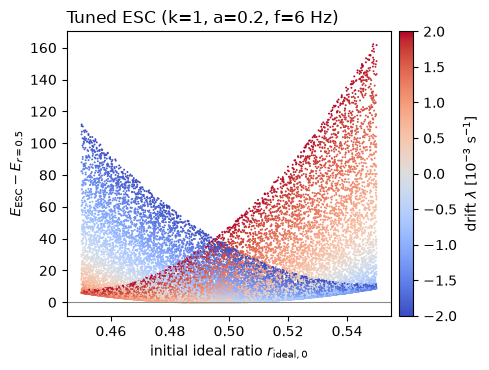

lam_avg = 1.26 1/s, L_dith = 0.066
ESC wins on 0.9839 of 100000 plants; median gain 13.09, worst case -0.37; convergence time median 6.82 s, max 9.67 s


In [ ]:
# Tuned ESC (k=1, a=0.2, f=6 Hz) on random plants (report Fig. 6b)
d = df_gain1amp02fre6.copy()
d['dE'] = d['energy_ESC'] - d['energy_const']
ds = d.sample(20000, random_state=0)     # subsample so the scatter stays readable

with plt.style.context('default'):
    fig, ax = plt.subplots(figsize=(5, 3.8))
    sc = ax.scatter(ds['r_ideal_0'], ds['dE'], c=ds['lambda_r_ideal'] * 1e3, cmap='coolwarm',
                    vmin=-2, vmax=2, s=2, lw=0, rasterized=True)
    ax.axhline(0, color=GR, lw=0.8)
    ax.set_xlabel(r'initial ideal ratio $r_\mathrm{ideal,0}$')
    ax.set_ylabel(r'$E_\mathrm{ESC}-E_{r=0.5}$')
    cb = fig.colorbar(sc, ax=ax, pad=0.02)
    cb.set_label(r'drift $\lambda$ [10$^{-3}$ s$^{-1}$]')
    ax.set_title('Tuned ESC (k=1, a=0.2, f=6 Hz)', loc='left')
    fig.tight_layout()
    # fig.savefig('oto_fixed_esc.png', dpi=300, bbox_inches='tight')
    plt.show()

lam = lam_avg(1, 6); L = dither_loss(0.2, 6)
print(f"lam_avg = {lam:.2f} 1/s, L_dith = {L:.3f}")
print(f"ESC wins on {d['choose_ESC'].mean():.4f} of {len(d)} plants; median gain {d['dE'].median():.2f}, "
      f"worst case {d['dE'].min():.2f}; convergence time median {d['convergence_time'].median():.2f} s, "
      f"max {d['convergence_time'].max():.2f} s")